In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins_raw.csv"
df = pd.read_csv(url)
df.head()

,studyName,Sample Number,Species,Region,Island,Stage,Individual ID,Clutch Completion,Date Egg,Culmen Length (mm),Culmen Depth (mm),Flipper Length (mm),Body Mass (g),Sex,Delta 15 N (o/oo),Delta 13 C (o/oo),Comments
0,PAL0708,1,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N1A1,Yes,2007-11-11,39.1,18.7,181.0,3750.0,MALE,NaN,NaN,Not enough blood for isotopes.
1,PAL0708,2,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N1A2,Yes,2007-11-11,39.5,17.4,186.0,3800.0,FEMALE,8.94956,-24.69454,NaN
2,PAL0708,3,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N2A1,Yes,2007-11-16,40.3,18.0,195.0,3250.0,FEMALE,8.36821,-25.33302,NaN
3,PAL0708,4,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N2A2,Yes,2007-11-16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Adult not sampled.
4,PAL0708,5,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N3A1,Yes,2007-11-16,36.7,19.3,193.0,3450.0,FEMALE,8.76651,-25.32426,NaN


In [3]:
df = df.rename(columns={
    "Species": "species",
    "Island": "island",
    "Sex": "sex",
    "Clutch Completion": "clutch_completion",
    "Culmen Length (mm)": "culmen_length",
    "Culmen Depth (mm)": "culmen_depth",
    "Flipper Length (mm)": "flipper_length",
    "Body Mass (g)": "body_mass",
    "Delta 15 N (o/oo)": "delta_15n",
    "Delta 13 C (o/oo)": "delta_13c",
})

df["species"] = df["species"].str.split().str[0] # To shorten the long species names let's only use the first word

num_cols = ["culmen_length", "culmen_depth", "flipper_length", "body_mass", "delta_15n", "delta_13c"]
cat_cols = ["species", "island", "sex", "clutch_completion"]

In [4]:
df[num_cols].agg(["min", "max", "mean", "median"]).round(2)

,culmen_length,culmen_depth,flipper_length,body_mass,delta_15n,delta_13c
min,32.10,13.10,172.00,2700.00,7.63,-27.02
max,59.60,21.50,231.00,6300.00,10.03,-23.79
mean,43.92,17.15,200.92,4201.75,8.73,-25.69
median,44.45,17.30,197.00,4050.00,8.65,-25.83


In [5]:
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    outliers = df[(df[col] < low) | (df[col] > high)]
    print(col, ":", len(outliers), "outliers")

culmen_length : 0 outliers
culmen_depth : 0 outliers
flipper_length : 0 outliers
body_mass : 0 outliers
delta_15n : 0 outliers
delta_13c : 0 outliers


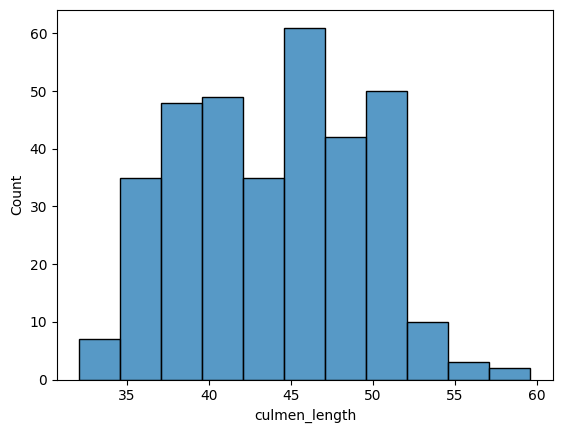

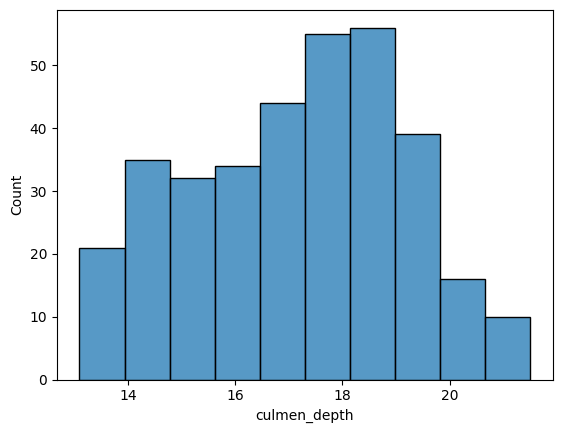

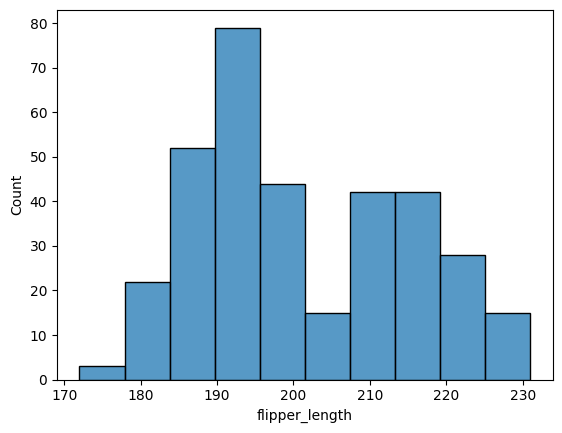

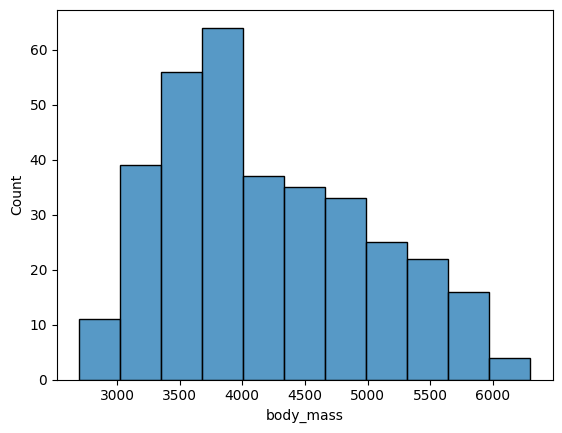

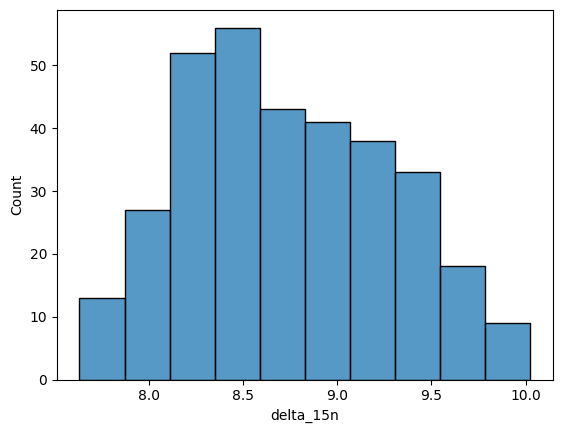

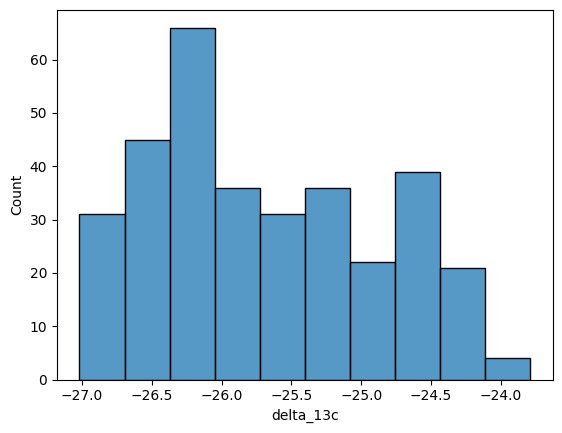

In [6]:
for col in num_cols:
  sns.histplot(data=df, x=col)
  plt.show()

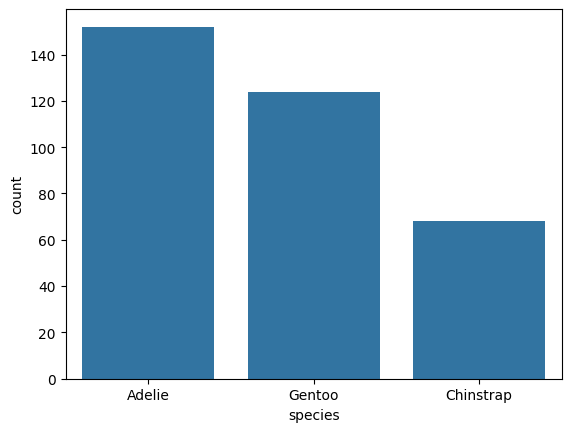

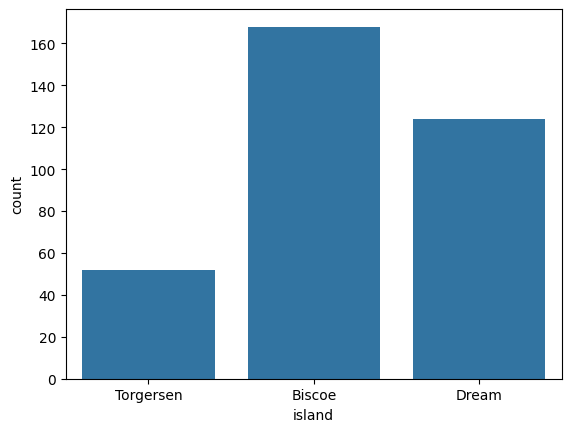

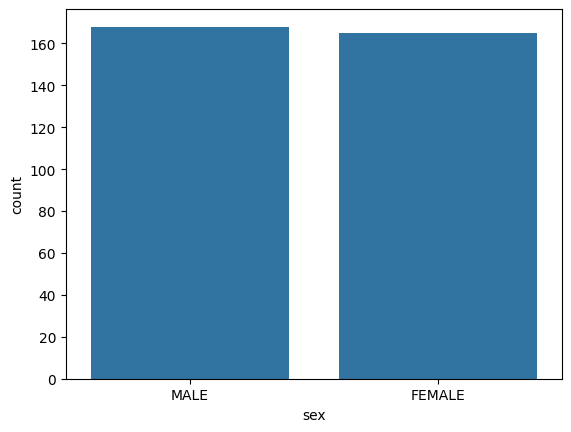

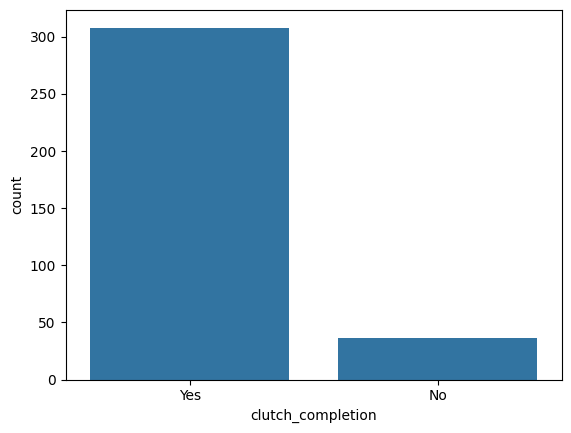

In [7]:
for col in cat_cols:
  sns.countplot(data=df, x=col)
  plt.show()

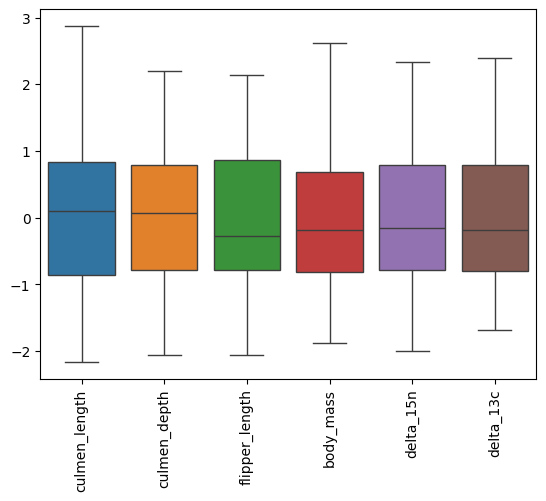

In [11]:
scaled = (df[num_cols] - df[num_cols].mean()) / df[num_cols].std() # Standardized so we can understand it better, doesnt show much otherwise.

sns.boxplot(data=scaled)
plt.xticks(rotation=90)
plt.show()

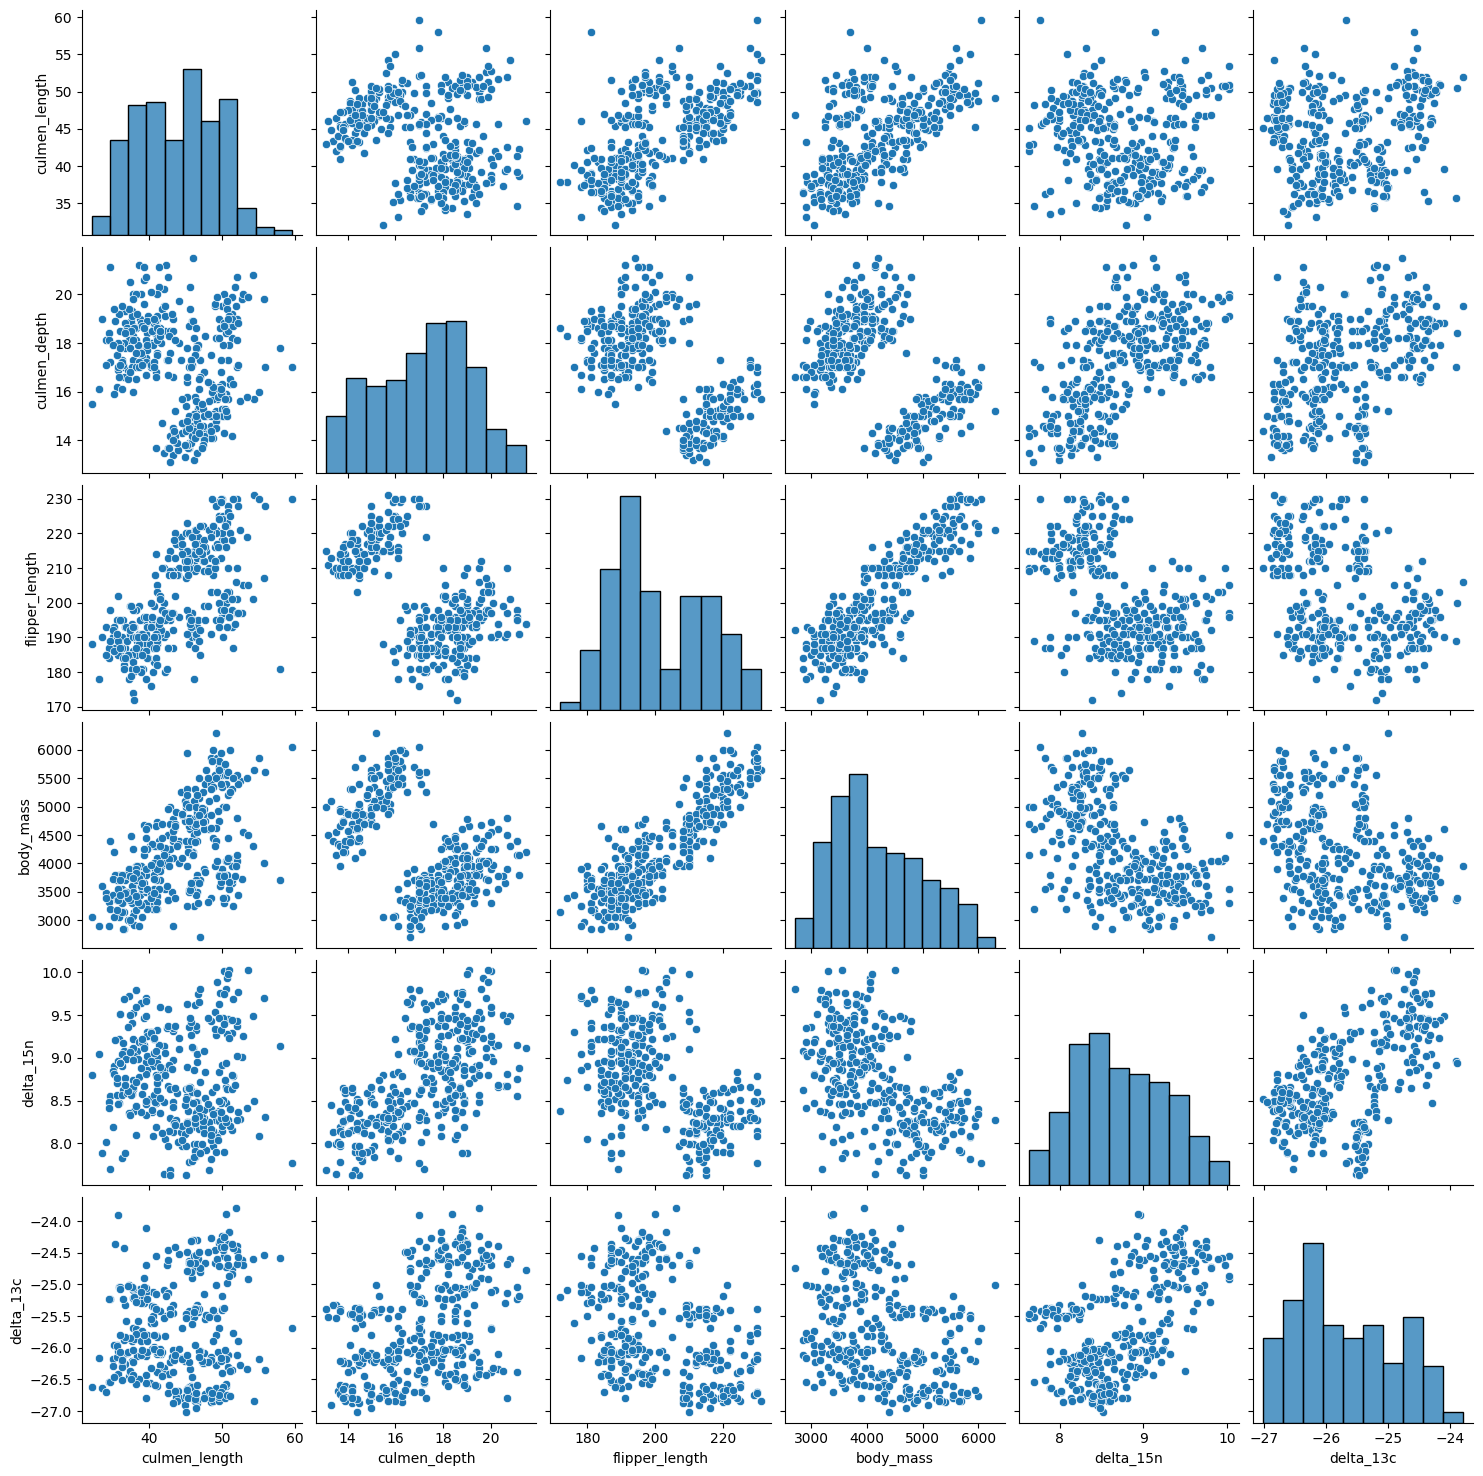

In [8]:
sns.pairplot(df[num_cols])
plt.show()

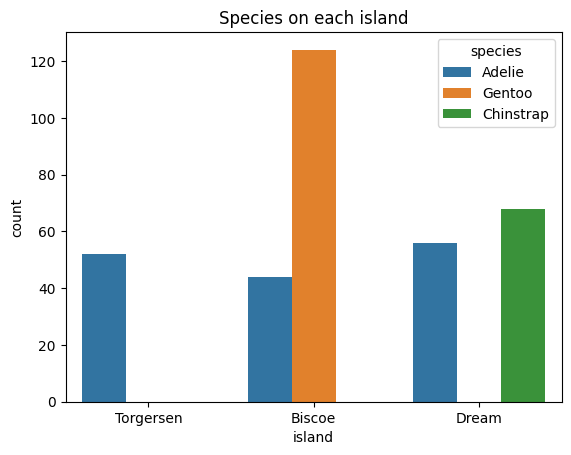

In [12]:
sns.countplot(data=df, x="island", hue="species")
plt.title("Species on each island")
plt.show()

In [13]:
df.groupby("species")["body_mass"].mean().round(1)

,body_mass
species,
Adelie,3700.7
Chinstrap,3733.1
Gentoo,5076.0


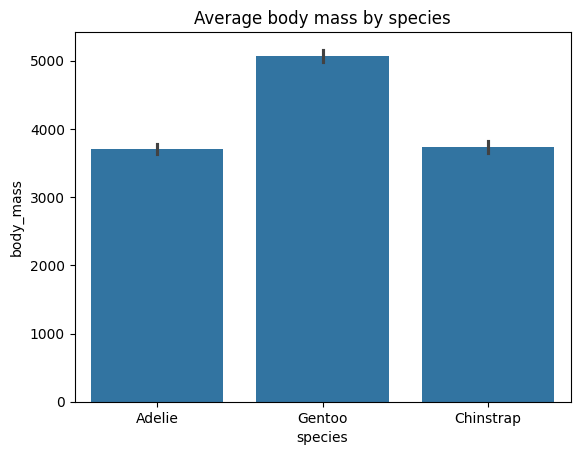

In [14]:
sns.barplot(data=df, x="species", y="body_mass")
plt.title("Average body mass by species")
plt.show()

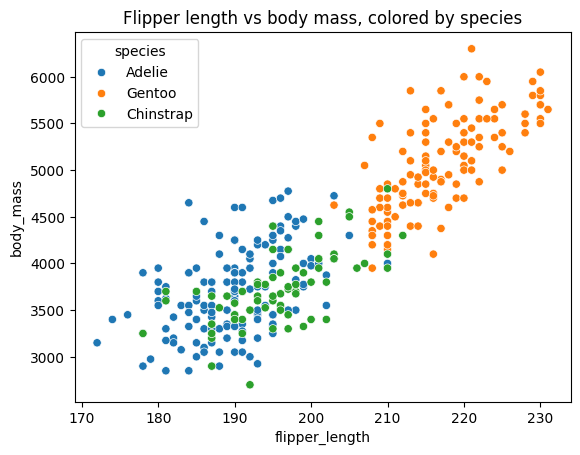

In [15]:
sns.scatterplot(data=df, x="flipper_length", y="body_mass", hue="species")
plt.title("Flipper length vs body mass, colored by species")
plt.show()